# 05: Unsupervised learning (Unit 5)

No labels this time. We ask what structure the **features** have on their own, and whether it lines up with districts, claim types or the scheme scores.

1. K-means (elbow + silhouette)
2. Hierarchical clustering (dendrogram)
3. DBSCAN (density-based)
4. PCA and t-SNE maps
5. Association rules (support / confidence / lift)

Unsupervised methods don't need a train/test split: nothing is being predicted. All 1,540 plots are used.

> **Honesty note.** The labels come from `backend/services/scheme_rules.py` plus Gaussian noise. They are not real scheme allocations or eligibility decisions. A model scoring near the **R² ceiling** has recovered those rules. That is the best possible result here, and it says nothing about real-world accuracy, because no real outcome data exists yet. A score *above* the ceiling would mean leakage.

## 0. Setup

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ML = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "fra_ml.py").exists() or (p / "ml" / "fra_ml.py").exists())
ML = ML if (ML / "fra_ml.py").exists() else ML / "ml"
sys.path.insert(0, str(ML))
from fra_ml import *

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (8, 4.5)})
pd.set_option("display.width", 200, "display.max_columns", 40)

df = load_data()
train, test = split(df)
print(f"train {len(train)} rows / {train.spatial_block.nunique()} blocks | test {len(test)} rows / {test.spatial_block.nunique()} blocks")
print("test rows per district:", test.district.value_counts().to_dict())

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
from mlxtend.frequent_patterns import apriori, association_rules
from backend.services.ml_features import add_engineered_features

E = add_engineered_features(X_of(df))
ENV = ["soil_ph", "oc_pct", "groundwater_stress_pct", "rainfall_mm_avg"]       # where the plot is
VIEWS = {"all 9 features": MODEL_FEATURES, "environment only (soil + climate)": ENV}
Z = {name: StandardScaler().fit_transform(E[cols]) for name, cols in VIEWS.items()}

train 1211 rows / 92 blocks | test 329 rows / 23 blocks
test rows per district: {'Adilabad': 80, 'Shivpuri': 74, 'West Tripura': 72, 'Chhindwara': 32, 'Kandhamal': 31, 'Warangal': 29, 'Koraput': 11}


## 1. K-means
K-means puts *k* centres in the data and assigns every plot to its nearest centre, then moves each centre to the mean of its plots, and repeats. It minimises **inertia**, the sum of squared distances to the centres.
- **Elbow:** inertia always falls as *k* grows. Look for the bend where extra clusters stop helping much.
- **Silhouette** (−1 to 1): for each plot, how much closer it is to its own cluster than to the next one. Higher means better-separated clusters.
- **ARI** (adjusted Rand index) compares clusters with a known grouping such as district: 1 = identical, 0 = no better than chance.

We run it on two feature views, because the binary claim-type columns can dominate distances.

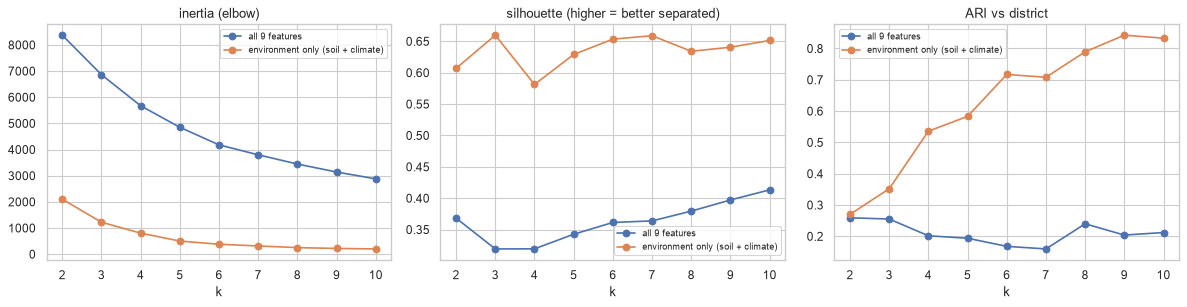

silhouette                                   ARI vs district                                   ARI vs claim_type                                  
view all 9 features environment only (soil + climate)  all 9 features environment only (soil + climate)    all 9 features environment only (soil + climate)
k                                                                                                                                                          
2             0.368                             0.607           0.259                             0.270            -0.001                            -0.001
3             0.319                             0.660           0.255                             0.352            -0.000                            -0.004
4             0.319                             0.581           0.202                             0.536            -0.001                            -0.004
5             0.343                             0.629           0.194                             0.583             0.135                            -0.007
6             0.361                             0.653           0.168                             0.717             0.220                            -0.002
7             0.364                             0.659           0.160                             0.708             0.215                            -0.003
8             0.379                             0.634           0.240                             0.789             0.177                            -0.001
9             0.397                             0.641           0.204                             0.843             0.171                            -0.001
10            0.413                             0.651           0.212                             0.833             0.147                            -0.001

In [2]:
ks = range(2, 11)
km_rows = []
for view, X in Z.items():
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        km_rows.append({"view": view, "k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_),
                        "ARI vs district": adjusted_rand_score(df.district, km.labels_),
                        "ARI vs claim_type": adjusted_rand_score(df.claim_type, km.labels_)})
km_tab = pd.DataFrame(km_rows)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for view, g in km_tab.groupby("view"):
    axes[0].plot(g.k, g.inertia, "o-", label=view); axes[1].plot(g.k, g.silhouette, "o-", label=view)
    axes[2].plot(g.k, g["ARI vs district"], "o-", label=view)
for ax, t in zip(axes, ["inertia (elbow)", "silhouette (higher = better separated)", "ARI vs district"]):
    ax.set_title(t); ax.set_xlabel("k"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
km_tab.round(3).pivot(index="k", columns="view", values=["silhouette", "ARI vs district", "ARI vs claim_type"])

k with best silhouette: {'all 9 features': 10, 'environment only (soil + climate)': 3}


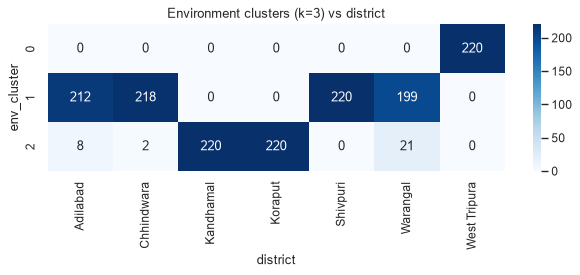

,soil_ph,soil_organic_carbon,groundwater_stress_pct,rainfall_mm_avg,pm_kisan,mgnrega,jjm,pmfby,pmksy,soil_health_card
env_cluster,,,,,,,,,,
0,5.4,20.1,40.0,2100.0,59.0,67.1,38.5,73.8,45.8,62.3
1,7.0,15.6,55.9,1012.9,56.0,62.3,73.9,52.3,70.5,42.8
2,6.1,30.1,32.4,1397.1,55.9,63.0,54.3,60.1,46.4,51.1


In [3]:
best_k = {view: int(g.loc[g.silhouette.idxmax(), "k"]) for view, g in km_tab.groupby("view")}
print("k with best silhouette:", best_k)
view = "environment only (soil + climate)"
km_env = KMeans(n_clusters=best_k[view], n_init=10, random_state=SEED).fit(Z[view])
df["env_cluster"] = km_env.labels_
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(pd.crosstab(df.env_cluster, df.district), annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title(f"Environment clusters (k={best_k[view]}) vs district"); plt.tight_layout(); plt.show()
profile = df.groupby("env_cluster")[["soil_ph", "soil_organic_carbon", "groundwater_stress_pct", "rainfall_mm_avg"] + TARGETS].mean()
profile.rename(columns=SHORT).round(1)

The cluster profile shows the **atlas** again, without using a single label: clusters built only from soil and climate line up with the dry/wet split from EDA F3, and their mean scheme scores differ accordingly.

## 2. Hierarchical clustering
Agglomerative clustering starts with every plot as its own cluster and repeatedly merges the closest pair. **Ward** linkage merges the pair whose union increases within-cluster variance the least. The **dendrogram** records the merge history: cutting it at a height gives a clustering, and long vertical gaps suggest natural cut points.

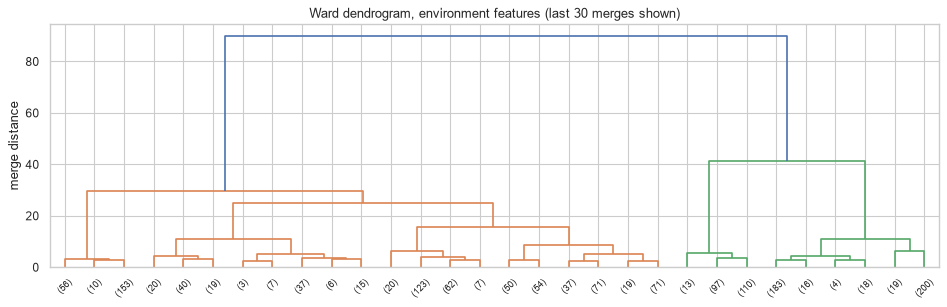

,silhouette,ARI vs district,ARI vs k-means
k,,,
2,0.606,0.275,0.977
3,0.664,0.363,0.931
4,0.583,0.546,0.957
5,0.626,0.585,0.984
6,0.650,0.722,0.983
7,0.653,0.715,0.958
8,0.622,0.794,0.933
9,0.631,0.857,0.961
10,0.640,0.842,0.945


In [4]:
X = Z["environment only (soil + climate)"]
L = linkage(X, method="ward")
fig, ax = plt.subplots(figsize=(12, 4))
dendrogram(L, truncate_mode="lastp", p=30, ax=ax, color_threshold=None, leaf_font_size=8)
ax.set_title("Ward dendrogram, environment features (last 30 merges shown)"); ax.set_ylabel("merge distance")
plt.tight_layout(); plt.show()
hc_rows = []
for k in ks:
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    hc_rows.append({"k": k, "silhouette": silhouette_score(X, lab), "ARI vs district": adjusted_rand_score(df.district, lab),
                    "ARI vs k-means": adjusted_rand_score(KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X), lab)})
pd.DataFrame(hc_rows).set_index("k").round(3)

## 3. DBSCAN
DBSCAN doesn't take *k*. It grows clusters through **dense** regions: a point with at least `min_samples` neighbours within distance `eps` is a *core* point, and points reachable from core points join its cluster. Points in sparse areas are labelled **noise (−1)**. To pick `eps`, sort every point's distance to its `min_samples`-th neighbour and look for the knee of that **k-distance curve**.

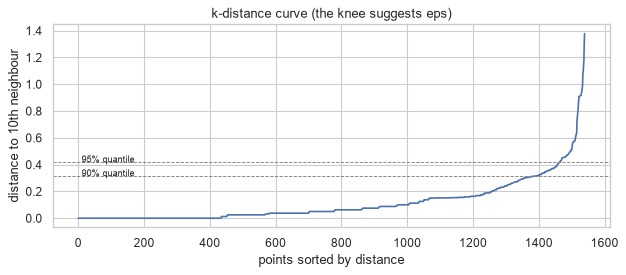

,eps,clusters,noise share,silhouette (non-noise),ARI vs district (non-noise)
0,0.100,19,0.318,0.573,0.737
1,0.200,11,0.127,0.760,0.947
2,0.300,11,0.058,0.609,0.803
3,0.500,6,0.015,0.635,0.850
4,0.800,5,0.006,0.611,0.729
5,0.313,10,0.045,0.667,0.799
6,0.416,8,0.021,0.659,0.811


In [5]:
MIN_SAMPLES = 10
kd = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)[0][:, -1])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(kd); ax.set_xlabel("points sorted by distance"); ax.set_ylabel(f"distance to {MIN_SAMPLES}th neighbour")
for q in (0.90, 0.95):
    ax.axhline(np.quantile(kd, q), ls="--", lw=0.8, color="grey"); ax.text(10, np.quantile(kd, q), f"{q:.0%} quantile", fontsize=8)
ax.set_title("k-distance curve (the knee suggests eps)"); plt.tight_layout(); plt.show()
db_rows = []
for eps in [0.1, 0.2, 0.3, 0.5, 0.8, np.quantile(kd, 0.9), np.quantile(kd, 0.95)]:
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X)
    n_cl = len(set(lab) - {-1}); mask = lab != -1
    db_rows.append({"eps": round(float(eps), 3), "clusters": n_cl, "noise share": (~mask).mean(),
                    "silhouette (non-noise)": silhouette_score(X[mask], lab[mask]) if n_cl > 1 else np.nan,
                    "ARI vs district (non-noise)": adjusted_rand_score(df.district[mask], lab[mask]) if n_cl > 1 else np.nan})
pd.DataFrame(db_rows).round(3)

**What DBSCAN shows here:** two of the four environment features are district constants, so each district sits on a thin "sheet" in feature space with empty gaps between districts. That is perfect territory for a density method. At `eps` 0.2 DBSCAN finds 11 dense groups with only 13% noise and ARI 0.95 against district, closer to the districts than k-means ever gets. The extra groups (11 vs 7 districts) come from imputed soil values piling up on single points inside Kandhamal and Koraput. At `eps` 0.1 a third of the plots become "noise"; at 0.8 neighbouring districts start to merge. Real, continuous data would rarely give density structure this clean: the sheets exist because the climate columns are constant per district.

## 4. PCA and t-SNE maps
- **PCA** is linear: the best flat 2-D shadow of the data. Its axes mean something (they are mixes of features).
- **t-SNE** is non-linear: it keeps *neighbours* close and lets distances between far-apart groups be arbitrary. It is good for seeing clusters, but cluster sizes and gaps on a t-SNE plot are **not** meaningful distances.

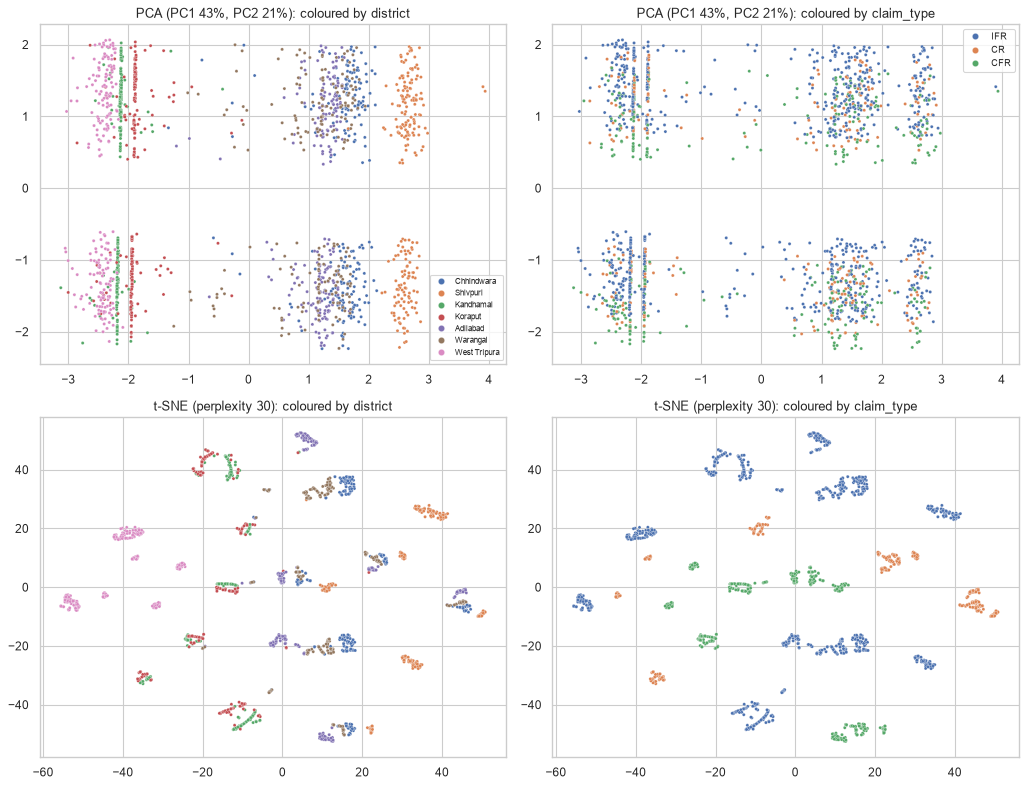

In [6]:
Xall = Z["all 9 features"]
P = PCA(n_components=2, random_state=SEED).fit(Xall)
pc = P.transform(Xall)
ts = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca").fit_transform(Xall)
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for row, (coords, name) in enumerate([(pc, f"PCA (PC1 {P.explained_variance_ratio_[0]:.0%}, PC2 {P.explained_variance_ratio_[1]:.0%})"), (ts, "t-SNE (perplexity 30)")]):
    sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df.district, s=8, ax=axes[row, 0], legend=(row == 0))
    sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df.claim_type, s=8, ax=axes[row, 1], legend=(row == 0))
    axes[row, 0].set_title(f"{name}: coloured by district"); axes[row, 1].set_title(f"{name}: coloured by claim_type")
axes[0, 0].legend(fontsize=7, markerscale=2); axes[0, 1].legend(fontsize=8, markerscale=2)
plt.tight_layout(); plt.show()

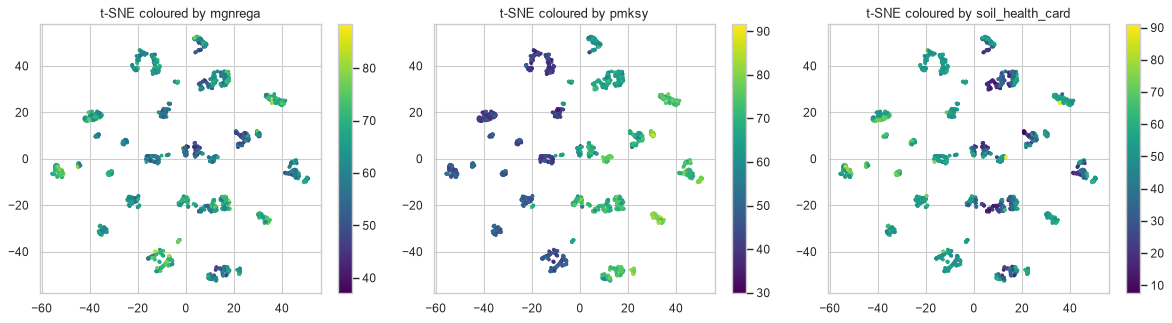

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, t in zip(axes, PRIMARY):
    s = ax.scatter(ts[:, 0], ts[:, 1], c=df[t], s=6, cmap="viridis"); plt.colorbar(s, ax=ax); ax.set_title(f"t-SNE coloured by {SHORT[t]}")
plt.tight_layout(); plt.show()

t-SNE separates plots into islands defined jointly by district (climate) and claim type. Colouring the islands by score shows which ones each scheme favours. This is the clearest picture of *why* the labels are mostly lookups: each island has its own score level.

## 5. Association rules
Turn each plot into a **basket** of yes/no items: its claim type, soil and climate bands, and whether each scheme score is in its top (HIGH) or bottom (LOW) third. Then find rules "if basket has A, it tends to have B":
- **support:** share of all plots that have both A and B.
- **confidence:** P(B | A), the share of plots with A that also have B.
- **lift:** confidence ÷ P(B). Lift 1 means A tells you nothing about B; lift 2.5 means B is 2.5× more likely when A is present.

Score bands here are descriptive terciles over all plots (nothing is being predicted).

In [8]:
items = pd.DataFrame({
    "IFR": df.claim_type == "IFR", "CFR": df.claim_type == "CFR", "CR": df.claim_type == "CR",
    "small holding (<=2 ha)": E.small_holding == 1,
    "acidic soil (pH<6.5)": E.ph_band == 0,
    "low OC (<1.5%)": E.oc_pct < 1.5, "high OC (>2%)": E.oc_pct > 2.0,
    "dry (<1000 mm)": df.rainfall_mm_avg < 1000, "wet (>1300 mm)": df.rainfall_mm_avg > 1300,
    "high gw stress (>=55%)": df.groundwater_stress_pct >= 55,
})
SCORE_ITEMS = []
for t in TARGETS:
    q = df[t].quantile([1/3, 2/3])
    items[f"{SHORT[t]} HIGH"] = df[t] > q.iloc[1]; items[f"{SHORT[t]} LOW"] = df[t] <= q.iloc[0]
    SCORE_ITEMS += [f"{SHORT[t]} HIGH", f"{SHORT[t]} LOW"]
freq = apriori(items, min_support=0.05, use_colnames=True, max_len=3)
rules = association_rules(freq, metric="confidence", min_threshold=0.8)
is_score = lambda s: any(x in SCORE_ITEMS for x in s)
only_score = lambda s: all(x in SCORE_ITEMS for x in s)
fmt = lambda s: ", ".join(sorted(s))
print(f"{len(freq)} frequent itemsets, {len(rules)} rules with confidence >= 0.8")

# (a) plot conditions -> a score band
cond_to_score = rules[rules.antecedents.apply(lambda a: not is_score(a)) & rules.consequents.apply(lambda c: len(c) == 1 and only_score(c))]
tab_a = cond_to_score.sort_values("lift", ascending=False).head(12)
display(tab_a.assign(**{"if": tab_a.antecedents.map(fmt), "then": tab_a.consequents.map(fmt)})[["if", "then", "support", "confidence", "lift"]].round(3))

708 frequent itemsets, 250 rules with confidence >= 0.8


,if,then,support,confidence,lift
156,"dry (<1000 mm), low OC (<1.5%)",jjm HIGH,0.143,0.948,2.847
157,"dry (<1000 mm), low OC (<1.5%)",pmksy HIGH,0.138,0.918,2.767
95,"dry (<1000 mm), small holding (<=2 ha)",jjm HIGH,0.112,0.887,2.662
96,"dry (<1000 mm), small holding (<=2 ha)",pmksy HIGH,0.106,0.845,2.548
31,"IFR, dry (<1000 mm)",jjm HIGH,0.138,0.845,2.536
10,dry (<1000 mm),jjm HIGH,0.240,0.839,2.518
188,"dry (<1000 mm), high gw stress (>=55%)",jjm HIGH,0.240,0.839,2.518
160,"high gw stress (>=55%), low OC (<1.5%)",jjm HIGH,0.162,0.838,2.517
67,"CFR, dry (<1000 mm)",jjm HIGH,0.053,0.837,2.512
37,"IFR, wet (>1300 mm)",pmksy LOW,0.197,0.837,2.509


In [9]:
# (b) a score band -> what those plots have in common
score_to_cond = rules[rules.antecedents.apply(lambda a: len(a) == 1 and only_score(a)) & rules.consequents.apply(lambda c: not is_score(c))]
tab_b = score_to_cond.sort_values(["confidence", "lift"], ascending=False).head(12)
display(tab_b.assign(**{"if": tab_b.antecedents.map(fmt), "then": tab_b.consequents.map(fmt)})[["if", "then", "support", "confidence", "lift"]].round(3))

,if,then,support,confidence,lift
13,pmksy LOW,wet (>1300 mm),0.334,1.000,2.333
0,pm_kisan HIGH,IFR,0.333,1.000,1.833
130,pmksy LOW,"acidic soil (pH<6.5), wet (>1300 mm)",0.331,0.992,2.336
7,pmksy LOW,acidic soil (pH<6.5),0.331,0.992,2.211
11,jjm LOW,wet (>1300 mm),0.329,0.984,2.297
124,jjm LOW,"acidic soil (pH<6.5), wet (>1300 mm)",0.326,0.977,2.300
5,jjm LOW,acidic soil (pH<6.5),0.326,0.977,2.177
14,jjm HIGH,high gw stress (>=55%),0.300,0.901,2.101
12,pmfby HIGH,wet (>1300 mm),0.284,0.855,1.996
6,pmfby HIGH,acidic soil (pH<6.5),0.284,0.855,1.907


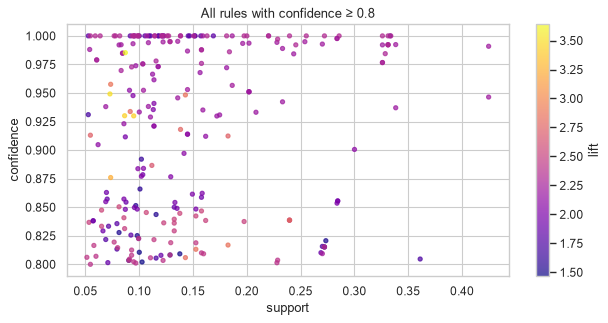

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sc = ax.scatter(rules.support, rules.confidence, c=rules.lift, cmap="plasma", s=14, alpha=0.7)
plt.colorbar(sc, label="lift"); ax.set_xlabel("support"); ax.set_ylabel("confidence")
ax.set_title("All rules with confidence ≥ 0.8"); plt.tight_layout(); plt.show()

Association rules **rediscover the scoring rules** without being told them: dry, high-stress districts → JJM/PMKSY HIGH; wet → PMKSY LOW; PM-KISAN HIGH → IFR. That is a useful check that the generator behaves as designed. It is also a reminder that "discovering" these patterns in synthetic data proves nothing about real plots.

## 6. Takeaways (numbers from the run above)
- **All 9 features: clusters ≠ districts.** Silhouette rises steadily with *k* (0.37 → 0.41 at k=10) with no clear elbow, and ARI against district stays ≤ 0.26. The binary claim-type and holding columns split the data as much as geography does.
- **Environment only: clusters = climate zones.** The silhouette peaks at **k=3 (0.66)**, which gives three clear groups:
  - **wet, acidic West Tripura:** 2,100 mm, pH 5.4.
  - **dry, high-stress MP + Telangana:** about 1,010 mm, 56% groundwater stress.
  - **Odisha:** about 1,400 mm, high organic carbon.

  Their mean scores reproduce the atlas without using a single label: JJM 74 in the dry group vs 39 in West Tripura, and PMFBY 74 vs 52. Raising *k* to 9 brings ARI vs district to 0.84.
- **Hierarchical (Ward) agrees with k-means** (ARI 0.93–0.98 between the two at every *k*).
- **DBSCAN matches districts best** (ARI 0.95 at eps 0.2), but only because the constant climate columns create artificial density sheets.
- **Association rules recover the generator's logic:**
  - PM-KISAN HIGH ⇒ IFR (confidence 1.0).
  - PMKSY LOW ⇒ wet (1.0).
  - dry + low organic carbon ⇒ JJM HIGH (0.95, lift 2.8).

  Note how **acidic soil** always appears together with **wet**. In this data the wet districts are the acidic ones, so no rule miner, and no model, can separate a rainfall effect from a pH effect. That is the same confound as EDA F5.